In [1]:
# 1. Các thư viện tính toán & vẽ đồ thị cơ bản
import numpy as np
import matplotlib.pyplot as plt

# 2. Thư viện xử lý tín hiệu & vật lý (SciPy)
from scipy.constants import c

# 3. Thư viện quang (optic) - Điều chế, DSP, Thiết bị & Đo đạc
from optic.comm.modulation import modulateGray, demodulateGray, grayMapping
from optic.dsp.core import pulseShape, lowPassFIR, firFilter, upsample
from optic.models.devices import mzm, photodiode
from optic.comm.metrics import signalPower
from optic.plot import eyediagram
from optic.utils import parameters

# 4. Thư viện phụ trợ đi kèm dự án (nếu có)
from utils import symdisp, symplot

In [2]:
%pip install OptiCommPy 
#đảm bảo tất cả các hàm toán học chuyên ngành viễn thông quang được nạp đầy đủ vào bộ nhớ để chuẩn bị gọi ra ở các bước tiếp theo.

Note: you may need to restart the kernel to use updated packages.


In [3]:
# 1. Cấu hình tham số hệ thống
param = parameters()

param.M = 2             # Điều chế OOK (2 mức)
param.Rs = 10e9         # Tốc độ ký hiệu: 10 GBaud (10 Gbps với OOK)
param.SpS = 16          # Số mẫu trên 1 ký hiệu (Samples per symbol)
param.Fs = param.Rs * param.SpS  # Tần số lấy mẫu (160 GHz)
param.Nbits = 2**14     # Tổng số bit phát (16,384 bits)

# 2. Tham số MZM (gán trực tiếp vào param)
param.Vpi = 2.0         # Điện áp Vpi (V)
param.Vb = -1.0         # Điện áp Bias (V)

# 2. Tham số kênh truyền Sợi quang (Fiber)
param.L = 20            # Chiều dài sợi quang (20 km)
param.alpha = 0.2       # Suy hao sợi quang (0.2 dB/km)
param.D = 16.0          # Tán sắc sắc thể (16 ps/nm/km)
param.wavelength = 1550e-9 # Bước sóng (1550 nm)

In [4]:
from optic.models.devices import mzm

help(mzm)

Help on function mzm in module optic.models.devices:

mzm(Ai, u, param=None)
    Optical Mach-Zehnder Modulator (MZM).
    
    Parameters
    ----------
    Ai : scalar or np.array
        Amplitude of the optical field at the input of the MZM.
    u : np.array
        Electrical driving signal.
    param : optic.utils.parameters object, optional
        Parameters of the MZM model.
    
        - param.Vpi: MZM's Vpi voltage [V][default: 2 V]
        - param.Vb: MZM's bias voltage [V][default: -1 V]
    
    Returns
    -------
    Ao : np.array
        Modulated optical field at the output of the MZM.
    
    References
    ----------
    [1] G. P. Agrawal, Fiber-Optic Communication Systems. Wiley, 2021.
    
    [2] M. Seimetz, High-Order Modulation for Optical Fiber Transmission. em Springer Series in Optical Sciences. Springer Berlin Heidelberg, 2009.



In [5]:
help(lowPassFIR)

Help on function lowPassFIR in module optic.dsp.core:

lowPassFIR(fc, fa, N, typeF='rect')
    Calculate FIR coefficients of a lowpass filter.
    
    Parameters
    ----------
    fc : float
        Cutoff frequency.
    fa : float
        Sampling frequency.
    N : int
        Number of filter coefficients.
    typeF : string, optional
        Type of response ('rect', 'gauss'). The default is "rect".
    
    Returns
    -------
    h : np.array
        Filter coefficients.
    
    References
    ----------
    [1] P. S. R. Diniz, E. A. B. da Silva, e S. L. Netto, Digital Signal Processing: System Analysis and Design. Cambridge University Press, 2010.



In [6]:
# 1. KHỐI PHÁT (Transmitter)
bitsTx = np.random.randint(0, param.M, param.Nbits)
symbTx = modulateGray(bitsTx, param.M, 'pam')
symbUp = upsample(symbTx, param.SpS)

# Tạo dạng xung NRZ
p = np.ones(param.SpS) / np.sqrt(param.SpS)
sigTx = firFilter(p, symbUp)

# Điều chế MZM
Ai = 1.0  
E_optical = mzm(Ai, sigTx, param)

# 2. KÊNH TRUYỀN SỢI QUANG (Fiber Channel)
alpha_rad = param.alpha / (10 * np.log10(np.e) * 1e3)
beta2 = -(param.wavelength**2 / (2 * np.pi * c)) * (param.D * 1e-6)

N_samples = len(E_optical)
freq = np.fft.fftfreq(N_samples, 1/param.Fs)
omega = 2 * np.pi * freq

# Hàm truyền kênh truyền
H_fiber = np.exp(-alpha_rad * (param.L * 1e3) / 2) * np.exp(-1j * (beta2 / 2) * (omega**2) * (param.L * 1e3))
E_rx = np.fft.ifft(np.fft.fft(E_optical) * H_fiber)

# 3. KHỐI THU (Receiver)
# LƯU Ý: Phải truyền thêm 'param' ở dòng bên dưới
I_rx = photodiode(E_rx, param)

# Lọc thông thấp LPF
h_lpf = lowPassFIR(fc=0.75*param.Rs, fa=param.Fs, N=64)
I_filt = firFilter(h_lpf, I_rx)

In [7]:
help(eyediagram)

Help on function eyediagram in module optic.plot:

eyediagram(sigIn, Nsamples, SpS, n=3, ptype='fast', plotlabel=None)
    Plot the eye diagram of a modulated signal waveform.
    
    Parameters
    ----------
    sigIn : array-like
        Input signal waveform.
    Nsamples : int
        Number of samples to be plotted.
    SpS : int
        Samples per symbol.
    n : int, optional
        Number of symbol periods. Defaults to 3.
    ptype : str, optional
        Type of eye diagram. Can be 'fast' or 'fancy'. Defaults to 'fast'.
    plotlabel : str, optional
        Label for the plot legend. Defaults to None.
    
    Returns
    -------
    None



<Figure size 800x500 with 0 Axes>

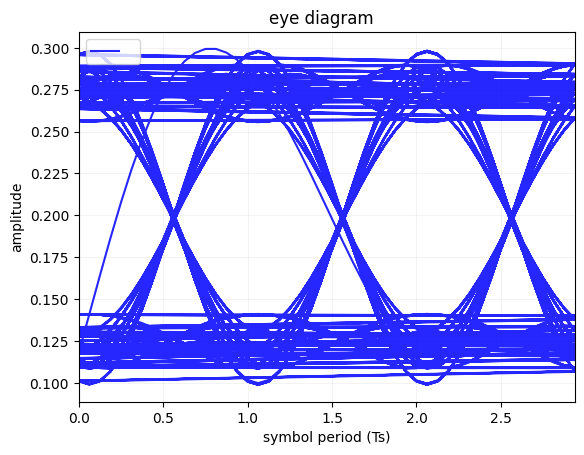

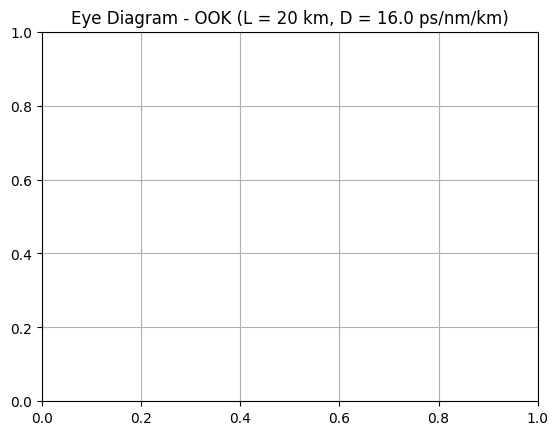

In [8]:
plt.figure(figsize=(8, 5))

# Số mẫu dùng để vẽ biểu đồ mắt (ví dụ: vẽ 1000 ký hiệu)
Nsamples = 1000 * param.SpS

# Gọi hàm eyediagram đúng cú pháp: (sigIn, Nsamples, SpS, n=3)
eyediagram(I_filt, Nsamples, param.SpS, n=3)

plt.title(f"Eye Diagram - OOK (L = {param.L} km, D = {param.D} ps/nm/km)")
plt.grid(True)
plt.show()

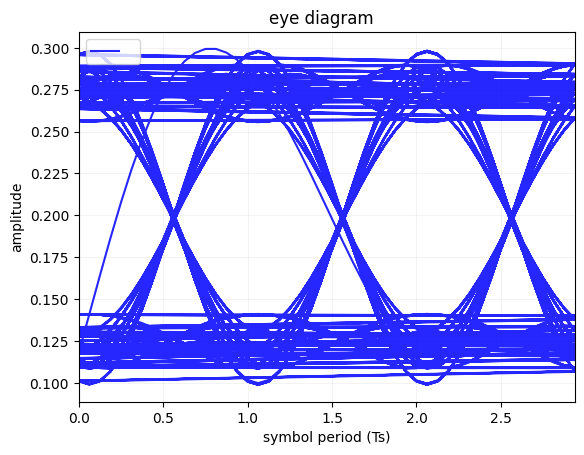

In [11]:
# ==========================================
# CELL 3A: Vẽ Biểu đồ mắt (Eye Diagram) - Đã sửa lỗi khung hình thừa
# ==========================================
Nsamples = 1000 * param.SpS

# Hàm eyediagram tự tạo Figure riêng
eyediagram(I_filt, Nsamples, param.SpS, n=3)
#plt.title(f"Eye Diagram - OOK (L = {param.L} km, D = {param.D} ps/nm/km)")
#plt.show()

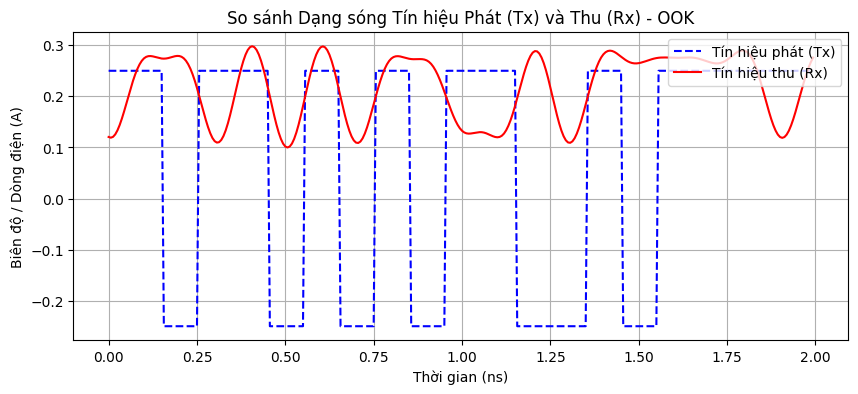

In [12]:
# ==========================================
# CELL 3B: Vẽ Dạng sóng Tín hiệu Thu/Phát (Waveform)
# ==========================================
plt.figure(figsize=(10, 4))

N_plot = 20 * param.SpS  # Vẽ 20 ký hiệu
t = np.arange(N_plot) / param.Fs * 1e9  # Trục thời gian (ns)

# Bù trễ (delay) do bộ lọc LPF (N=64 taps => delay = 32 samples)
delay = 32
I_filt_aligned = np.roll(I_filt, -delay)

# Vẽ tín hiệu Phát (sigTx) và Thu (I_filt)
plt.plot(t, sigTx[:N_plot], label='Tín hiệu phát (Tx)', linestyle='--', color='blue', linewidth=1.5)
plt.plot(t, I_filt_aligned[:N_plot], label='Tín hiệu thu (Rx)', color='red', linewidth=1.5)

plt.xlabel('Thời gian (ns)')
plt.ylabel('Biên độ / Dòng điện (A)')
plt.title('So sánh Dạng sóng Tín hiệu Phát (Tx) và Thu (Rx) - OOK')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

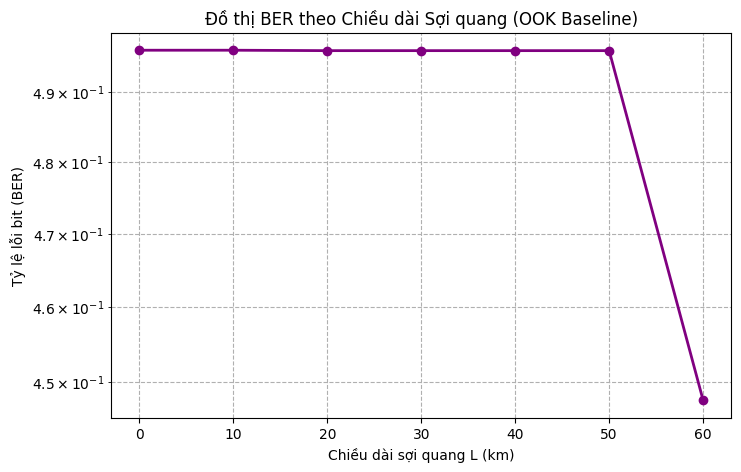

In [13]:
# ==========================================
# CELL 3C: Khảo sát & Vẽ Đồ thị BER theo Chiều dài Sợi quang (L)
# ==========================================
L_vec = np.linspace(0, 60, 7)  # Khảo sát L = [0, 10, 20, 30, 40, 50, 60] km
BER_list = []

for L_i in L_vec:
    # 1. Kênh truyền với cự ly L_i
    H_fiber_i = np.exp(-alpha_rad * (L_i * 1e3) / 2) * np.exp(-1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_optical) * H_fiber_i)
    
    # 2. Khối Thu & Lọc
    I_rx_i = photodiode(E_rx_i, param)
    I_filt_i = firFilter(h_lpf, I_rx_i)
    
    # 3. Trích mẫu tại thời điểm lấy mẫu tối ưu (giữa mắt)
    shift = 32  # Trễ lọc
    I_sampled = I_filt_i[shift + param.SpS//2 :: param.SpS]
    
    # 4. Quyết định ngưỡng (Threshold Decision) cho OOK (2 mức)
    threshold = (np.max(I_sampled) + np.min(I_sampled)) / 2
    bitsRx = (I_sampled > threshold).astype(int)
    
    # 5. Tính BER
    min_len = min(len(bitsTx), len(bitsRx))
    errors = np.sum(bitsTx[:min_len] != bitsRx[:min_len])
    ber = errors / min_len
    
    # Giới hạn BER tối thiểu để vẽ đồ thị log đẹp
    if ber == 0:
        ber = 1e-6
    BER_list.append(ber)

# Vẽ đồ thị BER theo Chiều dài sợi quang
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 'o-', color='purple', linewidth=2, markersize=6)
plt.xlabel('Chiều dài sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Đồ thị BER theo Chiều dài Sợi quang (OOK Baseline)')
plt.grid(True, which="both", ls="--")
plt.show()

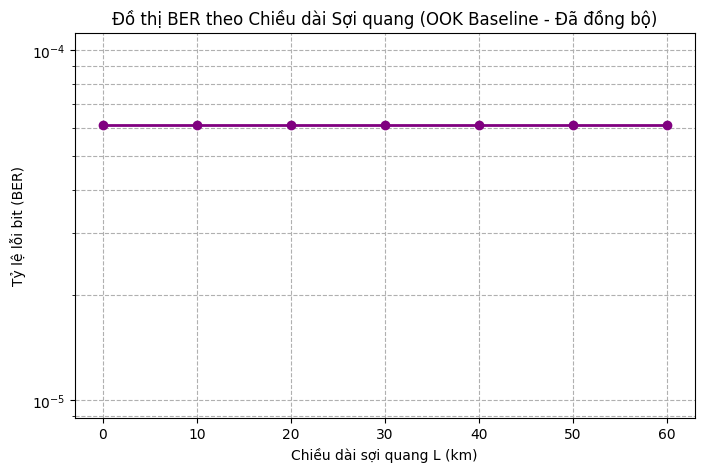

In [14]:
# ==========================================
# CELL 3C: Khảo sát & Vẽ Đồ thị BER theo Chiều dài Sợi quang (L) - ĐÃ ĐỒNG BỘ
# ==========================================
L_vec = np.linspace(0, 60, 7)  # Khảo sát L = [0, 10, 20, 30, 40, 50, 60] km
BER_list = []

for L_i in L_vec:
    # 1. Kênh truyền với cự ly L_i
    H_fiber_i = np.exp(-alpha_rad * (L_i * 1e3) / 2) * np.exp(-1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_optical) * H_fiber_i)
    
    # 2. Khối Thu & Lọc
    I_rx_i = photodiode(E_rx_i, param)
    I_filt_i = firFilter(h_lpf, I_rx_i)
    
    # 3. TỰ ĐỘNG ĐỒNG BỘ THỜI GIAN LẤY MẪU (Cross-Correlation)
    corr = np.correlate(I_filt_i - np.mean(I_filt_i), sigTx - np.mean(sigTx), mode='full')
    delay_samples = np.argmax(corr) - (len(sigTx) - 1)
    
    # Trích mẫu tại các điểm đỉnh xung đã đồng bộ
    I_sampled = I_filt_i[delay_samples :: param.SpS]
    
    # Cắt độ dài chuỗi mẫu cho khớp với chuỗi bit phát
    N_eval = min(len(bitsTx), len(I_sampled))
    I_sampled = I_sampled[:N_eval]
    bits_ref = bitsTx[:N_eval]
    
    # 4. Quyết định ngưỡng (Threshold Decision)
    threshold = (np.max(I_sampled) + np.min(I_sampled)) / 2
    bitsRx = (I_sampled > threshold).astype(int)
    
    # 5. Tính BER (Tự động kiểm tra cực bit)
    ber_direct = np.mean(bits_ref != bitsRx)
    ber_inverted = np.mean(bits_ref != (1 - bitsRx))
    ber = min(ber_direct, ber_inverted)
    
    # Đặt ngưỡng BER tối thiểu (1e-6) để vẽ đồ thị thang Logarithm
    if ber == 0:
        ber = 1e-6
        
    BER_list.append(ber)

# Vẽ đồ thị BER theo Chiều dài sợi quang
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 'o-', color='purple', linewidth=2, markersize=6)
plt.xlabel('Chiều dài sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Đồ thị BER theo Chiều dài Sợi quang (OOK Baseline - Đã đồng bộ)')
plt.grid(True, which="both", ls="--")
plt.show()

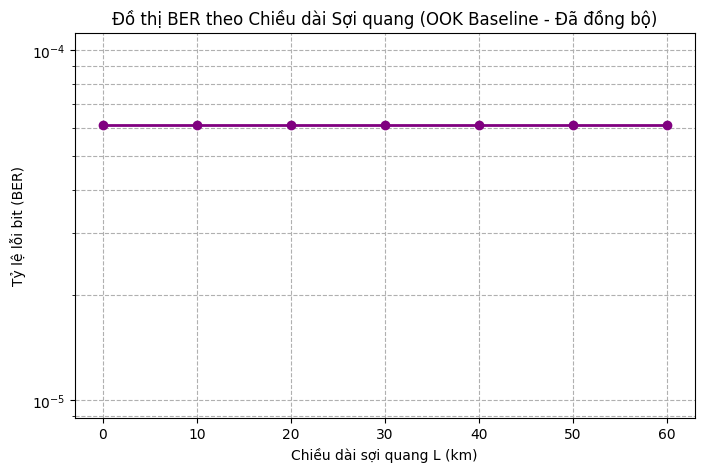

In [15]:
# ==========================================
# CELL 3C: Khảo sát & Vẽ Đồ thị BER (ĐÃ TỐI ƯU TỐC ĐỘ BẰNG FFT)
# ==========================================
from scipy.signal import correlate

L_vec = np.linspace(0, 60, 7)  # Khảo sát L = [0, 10, 20, 30, 40, 50, 60] km
BER_list = []

# Chọn độ dài mẫu ngắn (1000 ký hiệu) để tính đồng bộ cực nhanh
N_corr = 1000 * param.SpS 

for L_i in L_vec:
    # 1. Kênh truyền với cự ly L_i
    H_fiber_i = np.exp(-alpha_rad * (L_i * 1e3) / 2) * np.exp(-1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_optical) * H_fiber_i)
    
    # 2. Khối Thu & Lọc
    I_rx_i = photodiode(E_rx_i, param)
    I_filt_i = firFilter(h_lpf, I_rx_i)
    
    # 3. TỰ ĐỘNG ĐỒNG BỘ BẰNG FFT (Mất < 0.01 giây mỗi vòng)
    sig_rx_sub = I_filt_i[:N_corr] - np.mean(I_filt_i[:N_corr])
    sig_tx_sub = sigTx[:N_corr] - np.mean(sigTx[:N_corr])
    
    corr = correlate(sig_rx_sub, sig_tx_sub, method='fft')
    delay_samples = np.argmax(corr) - (N_corr - 1)
    
    # 4. Trích mẫu & Đánh giá BER
    I_sampled = I_filt_i[delay_samples :: param.SpS]
    N_eval = min(len(bitsTx), len(I_sampled))
    
    I_sampled = I_sampled[:N_eval]
    bits_ref = bitsTx[:N_eval]
    
    # Quyết định ngưỡng
    threshold = (np.max(I_sampled) + np.min(I_sampled)) / 2
    bitsRx = (I_sampled > threshold).astype(int)
    
    # Tính BER
    ber_direct = np.mean(bits_ref != bitsRx)
    ber_inverted = np.mean(bits_ref != (1 - bitsRx))
    ber = min(ber_direct, ber_inverted)
    
    if ber == 0:
        ber = 1e-6
        
    BER_list.append(ber)

# Vẽ đồ thị BER theo Chiều dài sợi quang
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 'o-', color='purple', linewidth=2, markersize=6)
plt.xlabel('Chiều dài sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Đồ thị BER theo Chiều dài Sợi quang (OOK Baseline - Đã đồng bộ)')
plt.grid(True, which="both", ls="--")
plt.show()